In [18]:
import torch
import torch.nn as nn
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [19]:
class WorldModelEBM(nn.Module):
    def __init__(self, context_dim, hidden_dim=256, n_flip_classes=4):
        super().__init__()
        self.context_encoder = nn.Sequential(
            nn.Linear(context_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.SiLU(),
        )
        self.flip_head = nn.Sequential(
            nn.Linear(hidden_dim, 128), nn.SiLU(), nn.Linear(128, n_flip_classes)
        )
        self.energy_head = nn.Sequential(
            nn.Linear(hidden_dim + 2, 128), nn.SiLU(), nn.Linear(128, 1)  # +2, pas +4
        )

    def encode_context(self, x):
        return self.context_encoder(x)

    def energy(self, x, y_pos):
        h = self.encode_context(x)
        return self.energy_head(torch.cat([h, y_pos], dim=-1))

    def flip_logits(self, x):
        h = self.encode_context(x)
        return self.flip_head(h)

In [20]:
def get_flip_labels(velocities):
    """
    cette fonction sert à labeliser les rebonds.
    velocities : (n_steps, 2)
    0 = no_flip, 1 = flip_x, 2 = flip_y, 3 = flip_both
    """
    v_t = velocities[:-1]
    v_next = velocities[1:]
    flip_x = ~np.isclose(v_t[:, 0], v_next[:, 0])
    flip_y = ~np.isclose(v_t[:, 1], v_next[:, 1])

    labels = np.zeros(len(v_t), dtype=np.int64)
    labels[flip_x & ~flip_y] = 1
    labels[~flip_x & flip_y] = 2
    labels[flip_x & flip_y] = 3
    return labels

In [21]:
def make_dataset(positions, velocities, context_len=3):
    """
    x = contexte aplati (context_len derniers states), dim context_len*4
    y_pos = vraie position suivante, dim 2
    flip_label = classe de transition de vitesse (0-3)
    """
    states = np.concatenate([positions, velocities], axis=-1)  # (n_steps, 4)
    flip_labels = get_flip_labels(velocities)                  # (n_steps-1,)

    contexts, true_pos_nexts, labels = [], [], []
    n = len(states)

    for t in range(context_len - 1, n - 1):
        ctx = states[t - context_len + 1 : t + 1]
        contexts.append(ctx.flatten())
        true_pos_nexts.append(positions[t + 1])
        labels.append(flip_labels[t])

    return (torch.tensor(np.stack(contexts), dtype=torch.float32),
            torch.tensor(np.stack(true_pos_nexts), dtype=torch.float32),
            torch.tensor(np.stack(labels), dtype=torch.long))

In [31]:
def sample_negatives_pos(model, x, y_pos_true, n_steps=50, step_size=0.07, noise_scale=0.007, box=(0.0,1.0)):
    batch = x.shape[0]
    half = batch // 2

    y_far = torch.empty(batch - half, 2).uniform_(box[0], box[1])
    y_near = y_pos_true[:half] + torch.randn(half, 2) * 0.1
    y_near = torch.clamp(y_near, box[0], box[1])
    y = torch.cat([y_near, y_far], dim=0).requires_grad_(True)

    for _ in range(n_steps):
        E = model.energy(x, y).sum()
        grad_y, = torch.autograd.grad(E, y)
        noise = torch.randn_like(y) * noise_scale
        y = (y - step_size * grad_y + noise).detach()
        y = torch.clamp(y, box[0], box[1])
        y = y.requires_grad_(True)

    return y.detach()

In [33]:
def train_world_model(model, positions, velocities, context_len=3, n_epochs=5000,
                       n_langevin_steps=50, step_size=0.07, noise_scale=0.007,
                       lr=1e-3, reg_weight=0.01, batch_size=64, box=(0.0, 1.0), margin=0.1):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    contexts, true_pos, flip_labels = make_dataset(positions, velocities, context_len=context_len)
    n_samples = contexts.shape[0]

    for epoch in range(n_epochs):
        idx = torch.randint(0, n_samples, (batch_size,))
        x_batch = contexts[idx]
        y_pos_true = true_pos[idx]
        labels_batch = flip_labels[idx]

        logits = model.flip_logits(x_batch)
        ce_loss = F.cross_entropy(logits, labels_batch)

        y_pos_neg = sample_negatives_pos(model, x_batch, y_pos_true, n_steps=n_langevin_steps,
                                          step_size=step_size, noise_scale=noise_scale, box=box)
        E_pos = model.energy(x_batch, y_pos_true)
        E_neg = model.energy(x_batch, y_pos_neg)
        contrastive = torch.relu(margin + E_pos - E_neg).mean()
        reg = reg_weight * (E_pos**2 + E_neg**2).mean()

        loss = ce_loss + contrastive + reg

        opt.zero_grad()
        loss.backward()
        opt.step()

        if epoch % 200 == 0:
            acc = (logits.argmax(-1) == labels_batch).float().mean().item()
            print(f"epoch {epoch:5d} | loss {loss.item():.4f} | ce {ce_loss.item():.4f} "
                  f"(acc={acc:.2f}) | contrastive {contrastive.item():.4f} | "
                  f"E_pos {E_pos.mean().item():.3f} | E_neg {E_neg.mean().item():.3f}")

    return model

In [24]:
def predict_next(model, context, vel_t, n_steps=50, step_size=0.07, box=(0.0, 1.0)):
    """
    context : (context_len, 4)
    vel_t : vitesse actuelle (2,)
    Retourne next_pos (2,), next_vel (2,)
    """
    x = context.flatten().unsqueeze(0)

    logits = model.flip_logits(x)
    predicted_class = logits.argmax(-1).item()

    next_vel = vel_t.clone()
    if predicted_class in (1, 3): next_vel[0] *= -1
    if predicted_class in (2, 3): next_vel[1] *= -1

    candidate = context[-1, :2].clone().unsqueeze(0).requires_grad_(True)
    for _ in range(n_steps):
        E = model.energy(x, candidate)
        grad, = torch.autograd.grad(E.sum(), candidate)
        candidate = (candidate - step_size * grad).detach()
        candidate = torch.clamp(candidate, box[0], box[1])
        candidate = candidate.requires_grad_(True)

    return candidate.detach().squeeze(0), next_vel

In [25]:
def rollout_world_model(model, positions0, velocities0, context_len, n_steps, box=(0.0, 1.0)):
    states0 = np.concatenate([positions0, velocities0], axis=-1)
    context = torch.tensor(states0[:context_len], dtype=torch.float32)
    vel_t = context[-1, 2:4].clone()

    predicted_states = [s.clone() for s in context]

    for _ in range(n_steps - context_len):
        next_pos, next_vel = predict_next(model, context, vel_t, box=box)
        next_state = torch.cat([next_pos, next_vel])
        predicted_states.append(next_state)

        context = torch.cat([context[1:], next_state.unsqueeze(0)], dim=0)
        vel_t = next_vel

    return torch.stack(predicted_states).numpy()

In [26]:
def simulate_bouncing_ball(n_steps=500, speed=0.09, angle=1.234, dt=0.01, box=(0.0, 1.0), seed=None):
    """
    Simule une balle rebondissant dans une boîte [box[0], box[1]]^2.
    Retourne les positions ET les vitesses (n_steps, 2) chacune --
    la vitesse est ici exposée explicitement dans le state, pas inférée.

    #n_steps : combien de points (positions successives) on veut générer dans la trajectoire
    #speed = 0.4 : vitesse de la balle (norme constante, sauf perte d'énergie si tu ajoutes un coefficient de restitution)
    #angle : angle initial du vecteur vitesse (en radians)
    #dt ("delta time") : le pas de temps entre deux positions
    #box : les limites de la boîte dans laquelle la balle rebondit
    #seed : graine aléatoire, pour la reproductibilité
    """

    rng = np.random.default_rng(seed)

    # point de départ aléatoire, avec une petite marge pour ne pas démarrer collé au mur
    margin = 0.1 * (box[1] - box[0])
    pos = rng.uniform(box[0] + margin, box[1] - margin, size=2)

    vel = speed * np.array([np.cos(angle), np.sin(angle)])  # vecteur vitesse initial (v_x, v_y)

    positions = [pos.copy()]
    velocities = [vel.copy()]

    # Effets de rebond
    for _ in range(n_steps - 1):
        pos = pos + vel * dt       # équation horaire
        for d in range(2):         # pour chaque axe (x, y)
            if pos[d] < box[0]:
                pos[d] = box[0] + (box[0] - pos[d])
                vel[d] *= -1
            elif pos[d] > box[1]:
                pos[d] = box[1] - (pos[d] - box[1])
                vel[d] *= -1
        positions.append(pos.copy())
        velocities.append(vel.copy())

    return np.stack(positions), np.stack(velocities)  # chacun (n_steps, 2)

In [27]:
context_len = 3
positions, velocities = simulate_bouncing_ball(n_steps=500, speed=0.09, angle=1.234, dt=0.01, seed=42)

model = WorldModelEBM(context_dim=context_len*4, hidden_dim=256)
model = train_world_model(model, positions, velocities, context_len=context_len, n_epochs=5000)

pred = rollout_world_model(model, positions, velocities, context_len, n_steps=500)

epoch     0 | loss 2.3246 | ce 1.3238 (acc=0.77) | contrastive 1.0007 | E_pos -0.096 | E_neg -0.097
epoch   200 | loss 1.0077 | ce 0.0000 (acc=1.00) | contrastive 1.0077 | E_pos 0.012 | E_neg 0.004
epoch   400 | loss 0.9990 | ce 0.0000 (acc=1.00) | contrastive 0.9990 | E_pos 0.023 | E_neg 0.024
epoch   600 | loss 1.0002 | ce 0.0000 (acc=1.00) | contrastive 1.0002 | E_pos 0.041 | E_neg 0.041
epoch   800 | loss 0.9997 | ce 0.0000 (acc=1.00) | contrastive 0.9997 | E_pos 0.011 | E_neg 0.011
epoch  1000 | loss 0.9998 | ce 0.0000 (acc=1.00) | contrastive 0.9998 | E_pos 0.017 | E_neg 0.017
epoch  1200 | loss 0.9987 | ce 0.0000 (acc=1.00) | contrastive 0.9987 | E_pos 0.019 | E_neg 0.020
epoch  1400 | loss 0.9966 | ce 0.0000 (acc=1.00) | contrastive 0.9965 | E_pos -0.011 | E_neg -0.008
epoch  1600 | loss 0.9983 | ce 0.0000 (acc=1.00) | contrastive 0.9983 | E_pos -0.003 | E_neg -0.002
epoch  1800 | loss 0.9989 | ce 0.0000 (acc=1.00) | contrastive 0.9989 | E_pos -0.007 | E_neg -0.006
epoch  2000 

In [29]:
context_len = 3
contexts, true_pos, flip_labels = make_dataset(positions, velocities, context_len=context_len)

x_test = contexts[:5]
y_close = true_pos[:5]
y_far = torch.rand(5, 2)

with torch.no_grad():
    e_close = model.energy(x_test, y_close)
    e_far = model.energy(x_test, y_far)

print("énergie position vraie :", e_close.squeeze())
print("énergie position aléatoire :", e_far.squeeze())

énergie position vraie : tensor([0.0032, 0.0032, 0.0032, 0.0032, 0.0032])
énergie position aléatoire : tensor([0.0946, 0.0252, 0.0454, 0.0249, 0.1485])


Ça confirme le diagnostic, et même de façon plus nette que prévu — regarde bien les deux lignes :

Signe le plus alarmant : e_close est EXACTEMENT identique sur 5 contextes différents (0.0032 × 5)
Ce n'est pas juste "l'énergie ne dépend pas bien de y" — c'est plus grave : l'énergie ne dépend quasiment pas non plus du contexte x puisque 5 contextes différents (5 endroits différents de la trajectoire) donnent une sortie identique au 4ème chiffre après la virgule. Le réseau semble avoir convergé vers une fonction quasi-constante, qui ignore en grande partie ses deux entrées.

e_far, elle, varie un peu (0.025 à 0.148) — donc il y a un peu de signal qui passe pour y, mais c'est faible et surtout ça ne va pas dans le bon sens : les positions aléatoires (censées être "fausses"/pénalisées) ont une énergie plus haute que la vraie position en moyenne, ce qui est la bonne direction, mais l'écart est minuscule (~0.02 à 0.14) par rapport à ce qu'on voudrait pour une vraie séparation nette.

Diagnostic confirmé : effondrement d'énergie (energy collapse), où le réseau a trouvé une solution paresseuse qui minimise la loss sans vraiment apprendre une fonction d'énergie informative. C'est un mode de défaillance très classique et documenté des EBM entraînés avec une loss contrastive mal régularisée.

Cause la plus probable ici : le reg_weight est trop faible pour empêcher l'effondrement, ou au contraire la régularisation pousse tout vers 0 sans que le contrastif ait assez de force pour créer un vrai écart

In [30]:
y_neg_test = sample_negatives_pos(model, x_test, n_steps=50, step_size=0.07, box=(0.0,1.0))
print("écart moyen positif vs négatif :", (y_neg_test - y_close).norm(dim=-1))

écart moyen positif vs négatif : tensor([0.0153, 0.0089, 0.0332, 0.0362, 0.0247])


Énergie plate → gradient quasi nul → Langevin ne bouge presque pas les négatifs → négatifs restent proches des positifs (voire aléatoires mais sans direction) → le contrastif n'a jamais un vrai signal fort pour pousser E_neg au-dessus de E_pos → l'énergie reste plate. C'est un point fixe dégénéré qui s'auto-entretient.

Pour casser ce cercle, il faut agir sur plusieurs fronts à la fois — un seul changement risque de ne pas suffire

1. Baisse le margin (1.0 → 0.1), comme évoqué — ça réduit l'ambition initiale de la loss, ce qui peut empêcher l'optimiseur "d'abandonner" trop vite vers le plateau.

2. Renforce le Langevin pendant l'entraînement (plus de pas, pas plus grand) pour forcer les négatifs à vraiment explorer, même avec un gradient faible :

In [34]:
context_len = 3
positions, velocities = simulate_bouncing_ball(n_steps=500, speed=0.09, angle=1.234, dt=0.01, seed=42)

model = WorldModelEBM(context_dim=context_len*4, hidden_dim=256)
model = train_world_model(model, positions, velocities, n_langevin_steps=100, step_size=0.15, context_len=context_len, n_epochs=5000)

pred = rollout_world_model(model, positions, velocities, context_len, n_steps=500)

epoch     0 | loss 1.4938 | ce 1.3818 (acc=0.00) | contrastive 0.1118 | E_pos -0.078 | E_neg -0.090
epoch   200 | loss 0.1009 | ce 0.0000 (acc=1.00) | contrastive 0.1008 | E_pos 0.005 | E_neg 0.004
epoch   400 | loss 0.0999 | ce 0.0000 (acc=1.00) | contrastive 0.0999 | E_pos -0.007 | E_neg -0.007
epoch   600 | loss 0.0994 | ce 0.0000 (acc=1.00) | contrastive 0.0993 | E_pos 0.005 | E_neg 0.006
epoch   800 | loss 0.1003 | ce 0.0000 (acc=1.00) | contrastive 0.1003 | E_pos 0.024 | E_neg 0.024
epoch  1000 | loss 0.0995 | ce 0.0000 (acc=1.00) | contrastive 0.0995 | E_pos 0.001 | E_neg 0.001
epoch  1200 | loss 0.0996 | ce 0.0000 (acc=1.00) | contrastive 0.0996 | E_pos 0.009 | E_neg 0.009
epoch  1400 | loss 0.1000 | ce 0.0000 (acc=1.00) | contrastive 0.1000 | E_pos -0.006 | E_neg -0.006
epoch  1600 | loss 0.0997 | ce 0.0000 (acc=1.00) | contrastive 0.0997 | E_pos -0.006 | E_neg -0.006
epoch  1800 | loss 0.0997 | ce 0.0000 (acc=1.00) | contrastive 0.0997 | E_pos -0.007 | E_neg -0.006
epoch  200

KeyboardInterrupt: 

Le pattern est identique à avant, juste borné par le nouveau margin (contrastive reste collé à 0.0993–0.1009, soit quasiment exactement margin=0.1, ce qui confirme E_pos ≈ E_neg en permanence). Donc baisser le margin et renforcer le Langevin n'a pas cassé l'effondrement — ça a juste déplacé le plateau. Le vrai problème est ailleurs, et je pense maintenant que c'est bien la piste que j'évoquais en premier : le déséquilibre de dimension entre h (256) et y_pos (2) dans la concaténation.

Pourquoi c'est probablement la vraie cause

Quand tu fais torch.cat([h, y_pos]), le vecteur résultant a 258 dimensions, dont seulement 2 portent l'information sur laquelle tu veux que le réseau discrimine. Au moment de l'initialisation des poids de energy_head, les poids connectés aux 2 dimensions de y_pos ont un gradient/signal noyé parmi les 256 dimensions de contexte — le réseau trouve qu'il est "plus facile" (moins de perte au début) d'ignorer y_pos et de produire une sortie qui dépend presque uniquement de h, ce qui donne une énergie constante par rapport à y_pos → exactement le collapse qu'on observe.

Le fix : projeter y_pos dans un espace de dimension comparable avant de concaténer, pour que son signal ne soit pas dilué :

In [35]:
class WorldModelEBM(nn.Module):
    def __init__(self, context_dim, hidden_dim=256, n_flip_classes=4, y_feat_dim=64):
        super().__init__()
        self.context_encoder = nn.Sequential(
            nn.Linear(context_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.SiLU(),
        )
        self.flip_head = nn.Sequential(
            nn.Linear(hidden_dim, 128), nn.SiLU(), nn.Linear(128, n_flip_classes)
        )
        self.y_proj = nn.Sequential(
            nn.Linear(2, y_feat_dim), nn.LayerNorm(y_feat_dim), nn.SiLU()
        )
        self.energy_head = nn.Sequential(
            nn.Linear(hidden_dim + y_feat_dim, 128), nn.SiLU(), nn.Linear(128, 1)
        )

    def encode_context(self, x):
        return self.context_encoder(x)

    def energy(self, x, y_pos):
        h = self.encode_context(x)
        y_feat = self.y_proj(y_pos)
        return self.energy_head(torch.cat([h, y_feat], dim=-1))

    def flip_logits(self, x):
        h = self.encode_context(x)
        return self.flip_head(h)

In [36]:
model = WorldModelEBM(context_dim=context_len*4, hidden_dim=256, y_feat_dim=64)
model = train_world_model(model, positions, velocities, context_len=context_len, n_epochs=5000,
                           n_langevin_steps=100, step_size=0.15, margin=0.1)

epoch     0 | loss 1.3864 | ce 1.2753 (acc=0.00) | contrastive 0.1110 | E_pos 0.022 | E_neg 0.011
epoch   200 | loss 0.0999 | ce 0.0000 (acc=1.00) | contrastive 0.0999 | E_pos 0.001 | E_neg 0.001
epoch   400 | loss 0.0999 | ce 0.0000 (acc=1.00) | contrastive 0.0998 | E_pos 0.005 | E_neg 0.005
epoch   600 | loss 0.0998 | ce 0.0000 (acc=1.00) | contrastive 0.0998 | E_pos 0.003 | E_neg 0.003
epoch   800 | loss 0.1000 | ce 0.0000 (acc=1.00) | contrastive 0.1000 | E_pos -0.008 | E_neg -0.008
epoch  1000 | loss 0.1000 | ce 0.0000 (acc=1.00) | contrastive 0.0999 | E_pos -0.007 | E_neg -0.007
epoch  1200 | loss 0.0999 | ce 0.0000 (acc=1.00) | contrastive 0.0999 | E_pos 0.043 | E_neg 0.043
epoch  1400 | loss 0.0998 | ce 0.0000 (acc=1.00) | contrastive 0.0998 | E_pos -0.009 | E_neg -0.008
epoch  1600 | loss 0.0998 | ce 0.0000 (acc=1.00) | contrastive 0.0998 | E_pos -0.005 | E_neg -0.005
epoch  1800 | loss 0.0998 | ce 0.0000 (acc=1.00) | contrastive 0.0998 | E_pos 0.018 | E_neg 0.019
epoch  2000 

Progrès réel, et intéressant à analyser : à partir de l'epoch ~2800, le modèle commence enfin à séparer E_pos et E_neg (regarde par exemple epoch 2800 : E_pos=-0.184 vs E_neg=0.223, un écart net de ~0.4 — complètement différent du plateau plat qu'on avait avant). Le fix de projection a donc bien aidé à sortir du collapse total.

Mais il reste un problème d'instabilité clair : le modèle oscille entre "a appris" et "recollapse"

Regarde la séquence : epoch 2800 (bon, écart 0.4) → epoch 3200 (retombé à plat, E_pos=E_neg=0.004) → epoch 3600 (bon à nouveau) → epoch 4000 (dégradé) → epoch 4200 (très bon, écart ~0.9) → epoch 4400 (dégradé) → epoch 4800 (bon, écart ~0.28). Ce n'est pas une convergence stable, c'est une oscillation — le modèle apprend, "désapprend", réapprend, sans jamais se stabiliser.

Cause probable de cette oscillation : le taux d'apprentissage (lr=1e-3) est trop élevé une fois que le modèle commence à bien discriminer

Une fois que E_pos et E_neg commencent à se séparer, les gradients contrastifs deviennent plus informatifs et plus grands — avec un lr fixe assez élevé, ça peut faire "overshoot" le bon point d'équilibre et retomber dans le mauvais minimum local plat, d'où l'oscillation.

Deux choses à essayer, dans cet ordre de priorité

1. Réduire le lr et/ou ajouter un scheduler qui le diminue progressivement
2. Simplement laisser tourner plus longtemps — vu que la tendance générale sur les 2000 dernières epochs est positive (les "bons" moments montrent des écarts de plus en plus grands : 0.4 → 0.9 → ...), il est possible que ça finisse par se stabiliser avec plus d'epochs, même sans toucher au lr.

Le plus important maintenant, avant de continuer à tuner l'entraînement : regarde le modèle au dernier epoch (4800) sur un vrai rollout

Le point clé pour ton diagnostic : le modèle du tout dernier epoch a E_pos=-0.127, E_neg=0.152 — un écart correct, pas le meilleur qu'on ait vu, mais pas nul non plus. Teste le rollout maintenant avec ce modèle, pour voir si même cet état "moyen" suffit à donner un comportement raisonnable :

In [52]:
class ReplayBuffer:
    def __init__(self, capacity, box=(0.0, 1.0)):
        self.capacity = capacity
        self.box = box
        self.buffer = torch.empty(0, 2)

    def sample(self, batch_size, reinit_prob=0.05):
        n_from_buffer = min(len(self.buffer), batch_size)
        if n_from_buffer > 0:
            idx = torch.randint(0, len(self.buffer), (n_from_buffer,))
            samples = self.buffer[idx].clone()
        else:
            samples = torch.empty(0, 2)

        n_new = batch_size - n_from_buffer
        if n_new > 0:
            new_samples = torch.empty(n_new, 2).uniform_(self.box[0], self.box[1])
            samples = torch.cat([samples, new_samples], dim=0)

        # ré-initialise aléatoirement une petite fraction, même parmi celles du buffer
        reinit_mask = torch.rand(batch_size) < reinit_prob
        samples[reinit_mask] = torch.empty(reinit_mask.sum(), 2).uniform_(self.box[0], self.box[1])

        return samples

    def push(self, samples):
        self.buffer = torch.cat([self.buffer, samples.detach()], dim=0)
        if len(self.buffer) > self.capacity:
            self.buffer = self.buffer[-self.capacity:]

In [53]:
def sample_negatives_pos(model, x, buffer, n_steps=20, step_size=0.1, noise_scale=0.005, box=(0.0, 1.0)):
    batch = x.shape[0]
    y = buffer.sample(batch).requires_grad_(True)

    for _ in range(n_steps):
        E = model.energy(x, y).sum()
        grad_y, = torch.autograd.grad(E, y)
        noise = torch.randn_like(y) * noise_scale
        y = (y - step_size * grad_y + noise).detach()
        y = torch.clamp(y, box[0], box[1])
        y = y.requires_grad_(True)

    buffer.push(y.detach())
    return y.detach()

In [54]:
def train_world_model(model, positions, velocities, context_len=3, n_epochs=5000,
                       n_langevin_steps=20, step_size=0.1, noise_scale=0.005,
                       lr=1e-3, reg_weight=0.01, batch_size=64, box=(0.0, 1.0), margin=0.1):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    buffer = ReplayBuffer(capacity=2000, box=box)

    contexts, true_pos, flip_labels = make_dataset(positions, velocities, context_len=context_len)
    n_samples = contexts.shape[0]

    for epoch in range(n_epochs):
        idx = torch.randint(0, n_samples, (batch_size,))
        x_batch = contexts[idx]
        y_pos_true = true_pos[idx]
        labels_batch = flip_labels[idx]

        logits = model.flip_logits(x_batch)
        ce_loss = F.cross_entropy(logits, labels_batch)

        y_pos_neg = sample_negatives_pos(model, x_batch, buffer, n_steps=n_langevin_steps,
                                          step_size=step_size, noise_scale=noise_scale, box=box)
        E_pos = model.energy(x_batch, y_pos_true)
        E_neg = model.energy(x_batch, y_pos_neg)
        contrastive = torch.relu(margin + E_pos - E_neg).mean()
        reg = reg_weight * (E_pos**2 + E_neg**2).mean()

        loss = ce_loss + contrastive + reg
        opt.zero_grad(); loss.backward(); opt.step()

        if epoch % 200 == 0:
            acc = (logits.argmax(-1) == labels_batch).float().mean().item()
            print(f"epoch {epoch:5d} | loss {loss.item():.4f} | ce {ce_loss.item():.4f} (acc={acc:.2f}) | "
                  f"contrastive {contrastive.item():.4f} | E_pos {E_pos.mean().item():.3f} | "
                  f"E_neg {E_neg.mean().item():.3f} | buffer_size {len(buffer.buffer)}")

    return model

In [55]:
def predict_next(model, context, vel_t, n_steps=50, step_size=0.07, box=(0.0, 1.0)):
    """
    context : (context_len, 4)
    vel_t : vitesse actuelle (2,)
    Retourne next_pos (2,), next_vel (2,)
    """
    x = context.flatten().unsqueeze(0)

    # 1. vitesse : classification déterministe (pas de gradient nécessaire)
    with torch.no_grad():
        logits = model.flip_logits(x)
        predicted_class = logits.argmax(-1).item()

    next_vel = vel_t.clone()
    if predicted_class in (1, 3): next_vel[0] *= -1
    if predicted_class in (2, 3): next_vel[1] *= -1

    # 2. position : descente de gradient sur l'énergie
    candidate = context[-1, :2].clone().unsqueeze(0).requires_grad_(True)
    for _ in range(n_steps):
        E = model.energy(x, candidate)
        grad, = torch.autograd.grad(E.sum(), candidate)
        candidate = (candidate - step_size * grad).detach()
        candidate = torch.clamp(candidate, box[0], box[1])
        candidate = candidate.requires_grad_(True)

    next_pos = candidate.detach().squeeze(0)

    return next_pos, next_vel


def rollout_world_model(model, positions0, velocities0, context_len, n_steps, box=(0.0, 1.0)):
    states0 = np.concatenate([positions0, velocities0], axis=-1)
    context = torch.tensor(states0[:context_len], dtype=torch.float32)
    vel_t = context[-1, 2:4].clone()

    predicted_states = [s.clone() for s in context]

    for _ in range(n_steps - context_len):
        next_pos, next_vel = predict_next(model, context, vel_t, box=box)
        next_state = torch.cat([next_pos, next_vel])
        predicted_states.append(next_state)

        context = torch.cat([context[1:], next_state.unsqueeze(0)], dim=0)
        vel_t = next_vel

    return torch.stack(predicted_states).numpy()

In [56]:
model = WorldModelEBM(context_dim=context_len*4, hidden_dim=256, y_feat_dim=64)
model = train_world_model(model, positions, velocities, context_len=context_len, n_epochs=5000)

epoch     0 | loss 1.4165 | ce 1.3146 (acc=0.00) | contrastive 0.1015 | E_pos 0.148 | E_neg 0.146 | buffer_size 64
epoch   200 | loss 0.0996 | ce 0.0000 (acc=1.00) | contrastive 0.0996 | E_pos -0.008 | E_neg -0.008 | buffer_size 2000
epoch   400 | loss 0.0998 | ce 0.0000 (acc=1.00) | contrastive 0.0997 | E_pos -0.002 | E_neg -0.002 | buffer_size 2000
epoch   600 | loss 0.0998 | ce 0.0000 (acc=1.00) | contrastive 0.0998 | E_pos 0.003 | E_neg 0.003 | buffer_size 2000
epoch   800 | loss 0.0999 | ce 0.0000 (acc=1.00) | contrastive 0.0999 | E_pos -0.004 | E_neg -0.004 | buffer_size 2000
epoch  1000 | loss 0.0999 | ce 0.0000 (acc=1.00) | contrastive 0.0999 | E_pos -0.008 | E_neg -0.007 | buffer_size 2000
epoch  1200 | loss 0.0999 | ce 0.0000 (acc=1.00) | contrastive 0.0999 | E_pos -0.010 | E_neg -0.010 | buffer_size 2000
epoch  1400 | loss 0.0999 | ce 0.0000 (acc=1.00) | contrastive 0.0998 | E_pos 0.015 | E_neg 0.016 | buffer_size 2000
epoch  1600 | loss 0.0999 | ce 0.0000 (acc=1.00) | contr

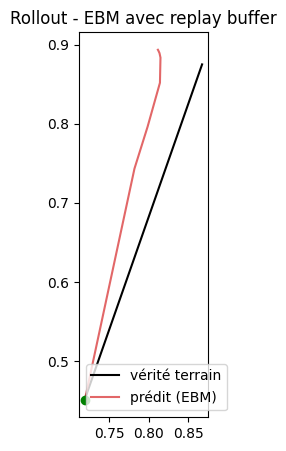

In [57]:
pred = rollout_world_model(model, positions, velocities, context_len, n_steps=500)

plt.figure(figsize=(5,5))
plt.plot(positions[:,0], positions[:,1], color="black", label="vérité terrain")
plt.plot(pred[:,0], pred[:,1], color="tab:red", alpha=0.7, label="prédit (EBM)")
plt.scatter(positions[0,0], positions[0,1], c="green", zorder=5)
plt.gca().set_aspect("equal")
plt.legend(); plt.title("Rollout - EBM avec replay buffer")
plt.show()